# **Project**
---
## **CleanSlate — Messy Dataset Cleanup**


# **🎯 Problem Statement**

A retail company stores customer information manually.

Over time, the dataset has become messy due to

- Missing values
- Duplicate records
- Wrong data types
- Inconsistent text values
Extra spaces
- Incorrect capitalization

As a Data Analyst, your task is to clean the dataset and generate useful business insights.

In [ ]:
# Import library
import numpy as np
import pandas as pd

In [ ]:
# Read dataset
df = pd.read_csv('https://github.com/YBIFoundation/Dataset/raw/main/CleanSlateMessyData.csv')

# **Step 1 - Inspect Dataset**

In [ ]:
# Step 1 - Inspect Dataset

In [ ]:
df.head()

,CustomerID,Name,Age,Gender,City,Salary,Department
0,1032,Vikas,51.0,MALE,Lucknow,39122.0,MARKETING
1,1110,Amit,56.0,FEMALE,Delhi,54961.0,MARKETING
2,1137,Rohan,42.0,FEMALE,Mumbai,70607.0,Marketing
3,1089,Neha,29.0,MALE,Jaipur,78574.0,it
4,1919,Neha,35.0,MALE,Delhi,118459.0,finance


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   CustomerID  1030 non-null   int64  
 1   Name        984 non-null    object 
 2   Age         980 non-null    float64
 3   Gender      1030 non-null   object 
 4   City        988 non-null    object 
 5   Salary      979 non-null    float64
 6   Department  1030 non-null   object 
dtypes: float64(2), int64(1), object(4)
memory usage: 56.5+ KB


In [ ]:
df.describe(include = 'all')

,CustomerID,Name,Age,Gender,City,Salary,Department
count,1030.000000,984,980.000000,1030,988,979.000000,1030
unique,NaN,40,NaN,6,17,NaN,18
top,NaN,Neha,NaN,female,Bangalore,NaN,FINANCE
freq,NaN,62,NaN,200,126,NaN,69
mean,1502.901942,NaN,39.728571,NaN,NaN,72369.727273,NaN
std,289.078041,NaN,11.438864,NaN,NaN,28090.786074,NaN
min,1001.000000,NaN,20.000000,NaN,NaN,25112.000000,NaN
25%,1252.250000,NaN,30.000000,NaN,NaN,48223.500000,NaN
50%,1505.500000,NaN,40.000000,NaN,NaN,70607.000000,NaN
75%,1752.750000,NaN,50.000000,NaN,NaN,96268.500000,NaN


In [ ]:
df.shape

(1030, 7)

In [ ]:
df.columns

Index(['CustomerID', 'Name', 'Age', 'Gender', 'City', 'Salary', 'Department'], dtype='object')

# **Step 2 - Find Missing Values**

In [ ]:
# Step 2 - Find Missing Values
df.isna().sum()

,0
CustomerID,0
Name,46
Age,50
Gender,0
City,42
Salary,51
Department,0


# **Step 3 - Fill Missing Values**

In [ ]:
df['Age'].mean()

np.float64(39.72857142857143)

In [ ]:
# Age
df['Age'].fillna(39.7)
df['Age'] = df['Age'].fillna(df['Age'].mean())

In [ ]:
# Salary
df['Salary'].median()

70607.0

In [ ]:
df['Salary'] = df['Salary'].fillna(df['Salary'].median())

In [ ]:
# Name
df['Name'] = df['Name'].fillna('Unknown')

In [ ]:
# City
df['City'].mode()[0]

'Bangalore'

In [ ]:
df['City'] = df['City'].fillna(df['City'].mode()[0])

In [ ]:
df.isna().sum()

,0
CustomerID,0
Name,0
Age,0
Gender,0
City,0
Salary,0
Department,0


# **Step 4 - Remove Duplicates**

In [ ]:
# Step 4 - Remove Duplicates
df.duplicated().sum()

np.int64(30)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.shape

(1000, 7)

# **Step 5 - Standardize Text**

In [ ]:
# Gender
df['Gender'] = df['Gender'].str.capitalize()

In [ ]:
# City
df['City'] = df['City'].str.strip()

In [ ]:
# Department
df['Department'] = df['Department'].str.upper()

# **Step 6 Rename Columns**

In [ ]:
df.columns

Index(['CustomerID', 'Name', 'Age', 'Gender', 'City', 'Salary', 'Department'], dtype='object')

In [ ]:
{'Salary':'MonthlySalary'}

{'Salary': 'MonthlySalary'}

In [ ]:
# df.rename()
df.rename(columns={'Salary':'MonthlySalary'},inplace=True)

In [ ]:
df.columns

Index(['CustomerID', 'Name', 'Age', 'Gender', 'City', 'MonthlySalary',
       'Department'],
      dtype='object')

# **Step 7 - Filter Dataset**

In [ ]:
# Employees with salary above 55,000
df['MonthlySalary']>55000

,MonthlySalary
0,False
1,False
2,True
3,True
4,True
...,...
1025,True
1026,False
1027,True
1028,True


In [ ]:
df[df['MonthlySalary']>55000]

,CustomerID,Name,Age,Gender,City,MonthlySalary,Department
2,1137,Rohan,42.000000,Female,Mumbai,70607.0,MARKETING
3,1089,Neha,29.000000,Male,Jaipur,78574.0,IT
4,1919,Neha,35.000000,Male,Delhi,118459.0,FINANCE
5,1236,Rahul,35.000000,Female,Mumbai,89425.0,SALES
6,1871,Vikas,40.000000,Female,Bangalore,56709.0,HR
...,...,...,...,...,...,...,...
1024,1872,Neha,32.000000,Female,Hyderabad,72788.0,FINANCE
1025,1088,Rahul,26.000000,Male,Mumbai,117764.0,FINANCE
1027,1467,Sanjana,39.728571,Female,Chennai,70607.0,SALES
1028,1122,Sanjana,51.000000,Male,Bangalore,109700.0,OPERATIONS


In [ ]:
# Sales Department
df['Department']=='SALES'

,Department
0,False
1,False
2,False
3,False
4,False
...,...
1025,False
1026,False
1027,True
1028,False


In [ ]:
df[df['Department']=='SALES']

,CustomerID,Name,Age,Gender,City,MonthlySalary,Department
5,1236,Rahul,35.000000,Female,Mumbai,89425.0,SALES
17,1665,Rakesh,53.000000,Male,Delhi,71313.0,SALES
25,1322,Sneha,53.000000,Male,Hyderabad,70607.0,SALES
26,1630,Sanjana,27.000000,Male,Lucknow,57854.0,SALES
27,1915,Ankit,29.000000,Female,Bangalore,75357.0,SALES
...,...,...,...,...,...,...,...
1000,1511,Riya,39.728571,Female,Delhi,111346.0,SALES
1001,1059,Priya,42.000000,Female,Jaipur,33155.0,SALES
1014,1386,Sanjana,51.000000,Male,Chennai,76913.0,SALES
1017,1492,Arjun,33.000000,Male,Chennai,87956.0,SALES


# **Step 8 - Analysis**

In [ ]:
# Average Salary
df['MonthlySalary'].mean()

np.float64(72423.77)

In [ ]:
# Department-wise Average Salary
df.groupby('Department')['MonthlySalary'].mean()

,MonthlySalary
Department,
FINANCE,69690.574586
HR,71439.261438
IT,71674.976331
MARKETING,73560.644578
OPERATIONS,74086.648045
SALES,74302.111842


In [ ]:
# City-wise Employees
df['City'].value_counts()

,count
City,
Bangalore,169
Hyderabad,130
Delhi,130
Pune,119
Chennai,116
Jaipur,110
Lucknow,109
Mumbai,109
nan,8


In [ ]:
# Average Age
df['Age'].mean()

np.float64(39.709428571428575)

# **Step 9 - Visualization**

<Axes: xlabel='Department'>

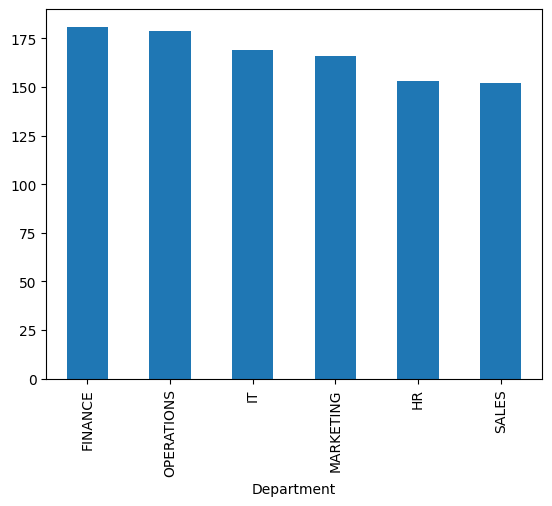

In [ ]:
# Department Count
df['Department'].value_counts().plot(kind='bar')

<Axes: ylabel='Frequency'>

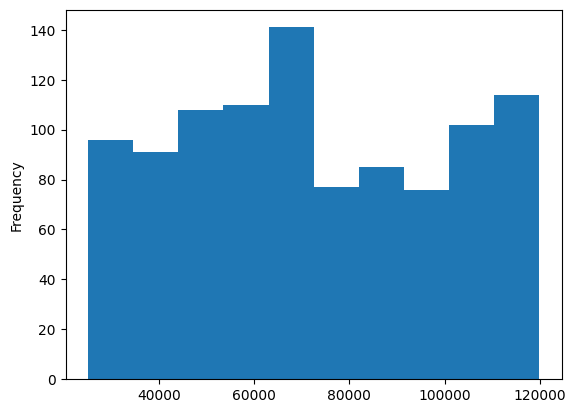

In [ ]:
# Salary Distribution
df['MonthlySalary'].plot(kind='hist')

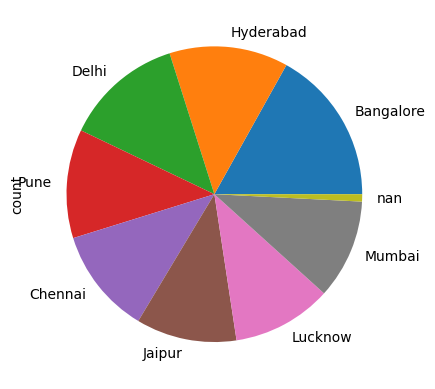

In [ ]:
# City Distribution
df['City'].value_counts().plot(kind='pie');

# **Step 10 - AutoEDA**

In [ ]:
!pip install ydata_profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 26.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.7/679.7 kB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 6.1 MB/s eta 0:00:00


In [ ]:
from ydata_profiling import ProfileReport
profile = ProfileReport(df,title='EDAReport')
profile.to_notebook_iframe()

/tmp/ipykernel_517/4033807096.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 7/7 [00:00<00:00, 87.48it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

# 😀
---

In [ ]:
# ADD A BONUS COLUMN[10% OF MONTHLYSALARY]
df['Bonus']=df['MonthlySalary']*0.1
df

,CustomerID,Name,Age,Gender,City,MonthlySalary,Department,Bonus
0,1032,Vikas,51.000000,Male,Lucknow,39122.0,MARKETING,3912.2
1,1110,Amit,56.000000,Female,Delhi,54961.0,MARKETING,5496.1
2,1137,Rohan,42.000000,Female,Mumbai,70607.0,MARKETING,7060.7
3,1089,Neha,29.000000,Male,Jaipur,78574.0,IT,7857.4
4,1919,Neha,35.000000,Male,Delhi,118459.0,FINANCE,11845.9
...,...,...,...,...,...,...,...,...
1025,1088,Rahul,26.000000,Male,Mumbai,117764.0,FINANCE,11776.4
1026,1331,Divya,45.000000,Male,Lucknow,26481.0,FINANCE,2648.1
1027,1467,Sanjana,39.728571,Female,Chennai,70607.0,SALES,7060.7
1028,1122,Sanjana,51.000000,Male,Bangalore,109700.0,OPERATIONS,10970.0


In [ ]:
# find top 10 highest paid employees
top_10_paid=df.nlargest(10,'MonthlySalary')
print(top_10_paid)

      CustomerID    Name        Age  Gender       City  MonthlySalary  \
1016        1414  Rakesh  58.000000    Male    Chennai       119876.0   
76          1031   Ankit  39.728571  Female    Chennai       119826.0   
698         1422    Amit  31.000000  Female    Chennai       119803.0   
784         1387   Kavya  48.000000    Male  Hyderabad       119776.0   
548         1432   Priya  43.000000  Female      Delhi       119767.0   
826         1942   Divya  56.000000    Male       Pune       119715.0   
552         1737   Priya  39.728571    Male     Jaipur       119636.0   
945         1477  Simran  45.000000    Male       Pune       119574.0   
508         1413  Simran  49.000000  Female    Lucknow       119426.0   
729         1151    Riya  42.000000  Female     Mumbai       119319.0   

      Department    Bonus  
1016          IT  11987.6  
76     MARKETING  11982.6  
698   OPERATIONS  11980.3  
784           IT  11977.6  
548   OPERATIONS  11976.7  
826    MARKETING  11971.5  


In [ ]:
# fin top 3 departments based on average salary
top_3_depts=df.groupby('Department')['MonthlySalary'].mean().nlargest(3)
print(top_3_depts)

Department
SALES         74302.111842
OPERATIONS    74086.648045
MARKETING     73560.644578
Name: MonthlySalary, dtype: float64


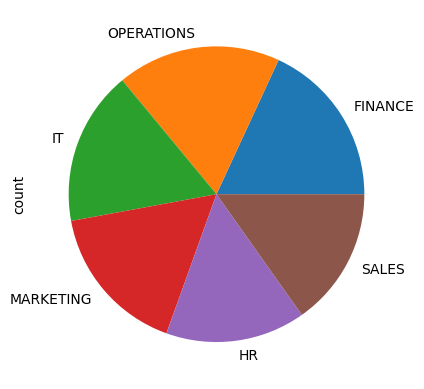

In [ ]:
# additional charts
df['Department'].value_counts().plot(kind='pie');


In [ ]:
## THANKYOU